# Tetiaroa TEM inversion from USF files

Two stations, a 3 m x 3 m loop with the receiver 13 m away, LM (1 A) and HM (10 A). Set `INCLUDE_LM` below to fit both moments or HM only.


In [10]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pytem').is_dir())
sys.path.insert(0, str(ROOT))

from pytem import read_usf, setup_shared_gate_matrices, invert_joint, cascade_filter
from pytem.survey import Survey
from pytem.plotter import plot_sounding, plot_survey_models, plot_survey_responses


## 1. Load data

In [11]:
tem = read_usf(str(ROOT / 'notebooks' / 'data' / 'tetiaroa'))
names = tem.data['SoundingName'].tolist()

print('Stations:', names)
for m in ['LM', 'HM']:
    t = tem.gate_times[m]['center']
    print(m, ':', t.size, 'gates from', t[0], 'to', t[-1], 's')

Stations: ['Line001_007', 'Line001_009']
LM : 6 gates from 1.0982e-05 to 2.97078e-05 s
HM : 22 gates from 2.25009e-05 to 0.0024417 s


Station map using pyTEM's `Survey.plot_map` with an OpenTopoMap background. Requires `contextily` and network access; the pyTEM helper falls back to a plain map if tiles are unavailable.


c:\WPy64-31180\python-3.11.8.amd64\Lib\site-packages\contextily\tile.py:662: UserWarning: The inferred zoom level of 21 is not valid for the current tile provider (valid zooms: 0 - 17).
  warnings.warn(msg)


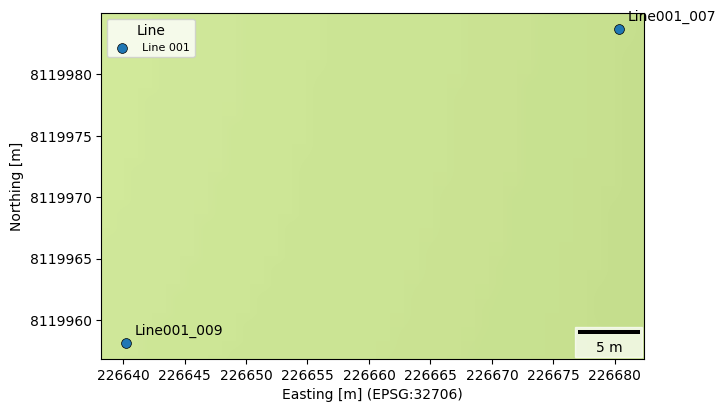

In [12]:
fig, ax = plt.subplots(figsize=(7, 7))
Survey(tem).plot_map(ax=ax, basemap=True)
east, north, _ = tem.utm_coords()
for name, x, y in zip(names, east, north):
    ax.annotate(name, (x, y), textcoords='offset points', xytext=(6, 6))
plt.show()


## 2. Plot the data

Voltage per ampere for the two moments. Crosses are gates that are not used: gates with a negative voltage, and the last two HM gates, which have a low signal and a large error bar in the file.

Where the moments overlap in time (about 22 to 30 microseconds) the LM voltage per ampere is about three times lower than the HM voltage. A single model cannot fit both, so only the HM data are inverted.

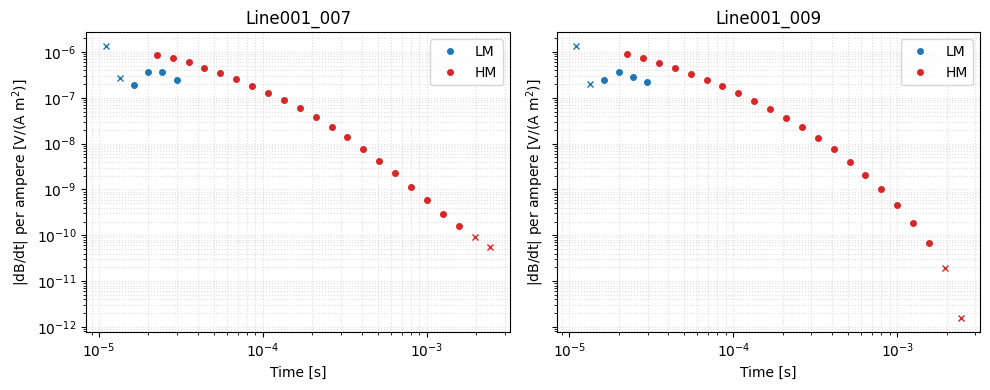

In [13]:
moments = ['LM', 'HM']
voltages = {m: tem.dbdt(m) for m in moments}
good = {m: np.isfinite(voltages[m]) & (voltages[m] > 0) for m in moments}
good['HM'][:, -2:] = False

fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4),
                         sharex=True, sharey=True, squeeze=False)
for station, ax in enumerate(axes.ravel()):
    for moment, color in [('LM', 'C0'), ('HM', 'C3')]:
        times = tem.gate_times[moment]['center']
        values = voltages[moment][station]
        used = good[moment][station]
        plot_sounding(times[used], values[used], ax=ax, labels=[moment],
                      styles=[color + 'o'], title=names[station],
                      ylabel=r'|dB/dt| per ampere [V/(A m$^2$)]')
        plot_sounding(times[~used], values[~used], ax=ax, styles=[color + 'x'],
                      title=names[station],
                      ylabel=r'|dB/dt| per ampere [V/(A m$^2$)]')
    ax.grid(True, which='both', ls=':', alpha=0.4)
fig.tight_layout()
plt.show()


## 3. Set up the inversion

- The current (10 A) and the receiver low-pass filter (450 kHz and 800 kHz) are taken from the `.usf` file (`/CURRENT` and `/LOW_PASS`).
- The model has 30 layers whose thicknesses increase with depth, down to 120 m.
- The starting model is a 10 ohm-m half-space.

In [18]:
INCLUDE_LM = True  # True: joint LM + HM inversion; False: HM only.
fit_moments = ['LM', 'HM'] if INCLUDE_LM else ['HM']
currents = {'LM': 1.0, 'HM': 10.0}
receiver_filter = cascade_filter(450_000.0, 800_000.0)
systems = {m: tem.to_pytem(m, peak_current=currents[m]) for m in fit_moments}

# Equivalent-area circular loop, using the shared HM geometry.
tx_radius = np.sqrt(systems['HM']['tx_size'] ** 2 / np.pi)
rx_x = abs(systems['HM']['rx_x'])
rx_y = abs(systems['HM']['rx_y'])

depths_top = np.concatenate([[0.0], np.logspace(0, np.log10(120.0), 29)])
thicknesses = np.diff(depths_top)
rho_start = np.full(depths_top.size, 10.0)

# Each selected moment has its own waveform/gate matrix on one time grid.
t_step, matrices = setup_shared_gate_matrices(systems, n_step=75)
print('Fitting:', ' + '.join(fit_moments))


Fitting: LM + HM


## 4. Invert

Call `invert_joint` directly for each station. `INCLUDE_LM` controls the fitted moments; raw data plots still show both for comparison. LM/HM retain separate currents, waveforms and gate masks. The final two HM gates remain excluded. The observed LM/HM mismatch may prevent a joint fit reaching RMS <= 1.


In [19]:
results = {}
for station, name in enumerate(names):
    fit_systems = []
    times, observed = {}, {}
    for moment in fit_moments:
        data = tem.to_pytem(moment, peak_current=currents[moment], station=station)
        used = good[moment][station]
        obs = data['obs_data'][used]
        fit_systems.append(
            {'M': matrices[moment][used], 'obs': obs, 'noise': 0.10 * obs})
        times[moment] = data['times'][used]
        observed[moment] = obs
    result = invert_joint(
        fit_systems, thicknesses=thicknesses, rho_start=rho_start, t_step=t_step,
        tx_size=tx_radius, geometry='circle_offset', rx_x=rx_x, rx_y=rx_y,
        rho_min=0.05, rho_max=1e4, maxit=50, transform='euler',
        system_filter=receiver_filter, verbose=False,
    )
    # Predictions follow the same moment order as fit_systems.
    boundaries = np.cumsum(result['n_gates'])[:-1]
    predicted = dict(zip(fit_moments, np.split(result['predicted'], boundaries)))
    result.update(times=times, obs=observed, pred=predicted)
    results[station] = result
    print(name, ': RMS =', round(result['rms'], 2),
          ', converged =', result['converged'])


Line001_007 : RMS = 2.71 , converged = False
Line001_009 : RMS = 2.64 , converged = False


## 5. Results

Resistivity against depth for each station. The deepest layers are poorly constrained by the data.

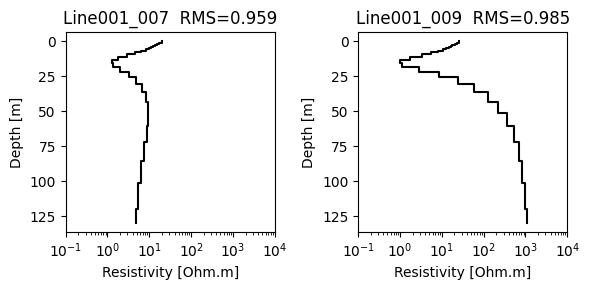

In [16]:
models = np.array([results[s]['resistivities'] for s in range(len(names))])
rms = np.array([results[s]['rms'] for s in range(len(names))])

fig, axes = plot_survey_models(
    thicknesses, models, rms=rms, station_names=names,
    n_cols=len(names), xlim=(0.1, 1e4), model_linestyle='-')
for ax in axes[1:]:
    ax.sharex(axes[0])
    ax.sharey(axes[0])
plt.show()


Measured data (points) and the response of the final model (lines), in V/m$^2$.

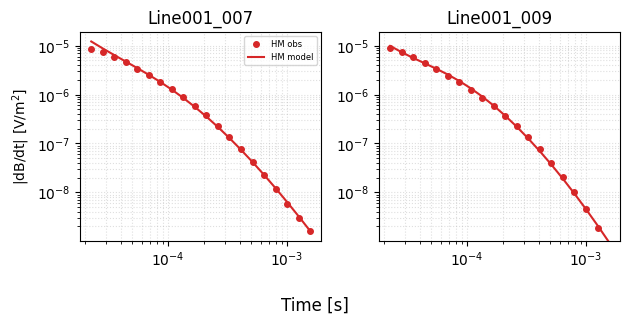

In [17]:
fig, axes = plot_survey_responses(results, n_cols=len(names))
for ax, name in zip(axes, names):
    ax.set_title(name)
plt.show()
